# 02 - Results Analysis

Compare the six training runs (2 models × 3 imbalance strategies). The headline
question: *does handling class imbalance actually help the model catch the
rare, dangerous classes (especially melanoma)?*

**Prerequisite.** Run the experiment matrix first:

```bash
python train.py --model simple_cnn --imbalance none          --run-name cnn_none
python train.py --model simple_cnn --imbalance weighted_loss  --run-name cnn_weighted
python train.py --model simple_cnn --imbalance oversampling   --run-name cnn_oversample
python train.py --model resnet18   --imbalance none          --run-name resnet_none
python train.py --model resnet18   --imbalance weighted_loss  --run-name resnet_weighted
python train.py --model resnet18   --imbalance oversampling   --run-name resnet_oversample
```
Each writes `logs/<run>.csv` and `models/<run>.pt`.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import yaml
CFG = yaml.safe_load(Path("config.yaml").read_text())
IMAGES_DIR = Path(CFG["data"]["raw_dir"]) / "images"
SPLITS_CSV = CFG["data"]["splits_csv"]
print("project root:", ROOT)


project root: /home/aproia/AML-HAM10000


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
LOGS = Path(CFG["paths"]["logs_dir"]); MODELS = Path(CFG["paths"]["models_dir"])
runs = sorted(p.stem for p in LOGS.glob("*.csv"))
print("found runs:", runs)

found runs: ['cnn_none', 'cnn_oversample', 'cnn_weighted', 'resnet_none', 'resnet_oversample', 'resnet_weighted']


## 0. Non-ML & classical baselines

Before judging the CNNs we establish reference points that involve **no deep
learning**.

- **Dummy (majority)** — always predict `nv`. We expect it to score high *accuracy*,
  ~0 macro-F1 and **zero melanoma recall**: the clearest demonstration
  that accuracy is the wrong metric here.
- **Dummy (stratified)** — random guesses from the class priors.
- **Classical ML (Logistic Regression / Random Forest)** — classifications based on colour
  histogram + summary-statistic features (see `src/baselines.py`) fed to a
  shallow classifier.

All baselines are evaluated on the **same test split** with the **same
metrics** as the CNNs (`src.evaluate.compute_metrics`), so every row of the
final table is directly comparable.

In [3]:
import pandas as pd, numpy as np
from src.baselines import (
    build_dummy, build_classical, extract_feature_matrix, predict_proba_aligned,
)
from src.evaluate import compute_metrics, per_class_report
from src.dataset import CLASSES

full = pd.read_csv(SPLITS_CSV)
train_df = full[full.split == "train"]
test_df  = full[full.split == "test"]

Xtr, ytr = extract_feature_matrix(train_df, IMAGES_DIR)
Xte, yte = extract_feature_matrix(test_df,  IMAGES_DIR)
print("feature matrix:", Xtr.shape)


features:   0%|          | 0/7002 [00:00<?, ?it/s]


features:   0%|          | 15/7002 [00:00<00:47, 146.45it/s]


features:   0%|          | 30/7002 [00:00<00:48, 145.12it/s]


features:   1%|          | 45/7002 [00:00<00:48, 142.80it/s]


features:   1%|          | 60/7002 [00:00<00:49, 141.03it/s]


features:   1%|          | 75/7002 [00:00<00:48, 142.09it/s]

... (522 outputs left out)


features:  98%|█████████▊| 1455/1481 [00:09<00:00, 157.76it/s]


features:  99%|█████████▉| 1472/1481 [00:09<00:00, 158.81it/s]


features: 100%|██████████| 1481/1481 [00:09<00:00, 153.12it/s]

feature matrix: (7002, 102)


In [4]:
baseline_results, baseline_preds = {}, {}

specs = {
    "dummy_majority":   build_dummy("most_frequent"),
    "dummy_stratified": build_dummy("stratified"),
    "classical_logreg": build_classical("logreg"),
    "classical_rf":     build_classical("rf"),
}
for name, clf in specs.items():
    clf.fit(Xtr, ytr)
    y_prob = predict_proba_aligned(clf, Xte)
    y_pred = y_prob.argmax(1)
    baseline_results[name] = compute_metrics(yte, y_pred, y_prob)
    baseline_preds[name] = (yte, y_pred, y_prob)

base_table = pd.DataFrame(baseline_results).T
display(base_table.round(4))

,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_auc_ovr
dummy_majority,0.6698,0.1429,0.1146,0.5374,0.5000
dummy_stratified,0.4720,0.1343,0.1349,0.4717,0.4952
classical_logreg,0.5246,0.4612,0.3413,0.5885,0.8303
classical_rf,0.6536,0.4291,0.4077,0.6806,0.8787


## 1. Training curves

Loss and validation macro-F1 over epochs. We watch for the train/val gap and confirm early stopping kicked in sensibly.

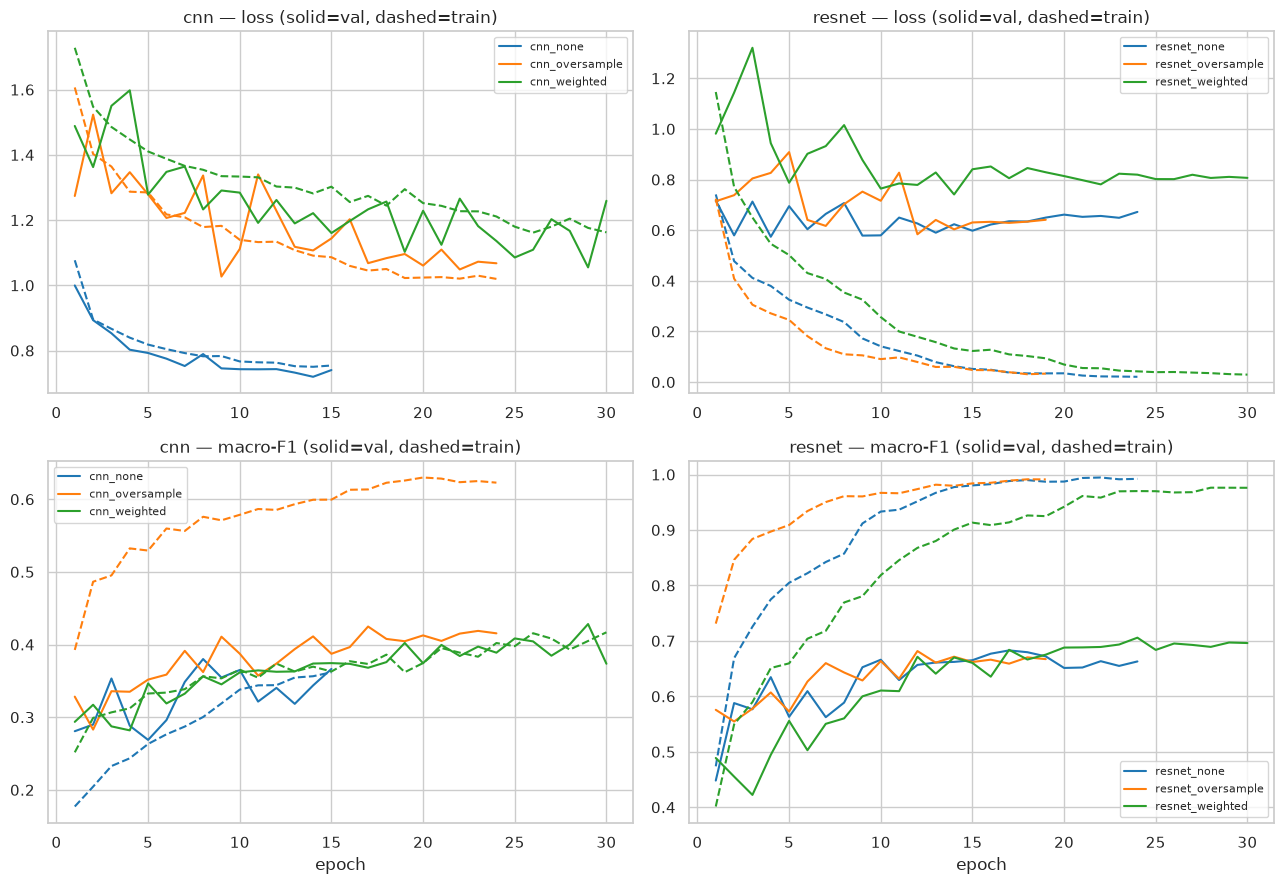

In [5]:
families = [("cnn", [r for r in runs if r.startswith("cnn")]),
            ("resnet", [r for r in runs if r.startswith("resnet")])]
colors = plt.cm.tab10.colors

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for col, (fam, fam_runs) in enumerate(families):
    for i, run in enumerate(fam_runs):
        h = pd.read_csv(LOGS / f"{run}.csv")
        c = colors[i % len(colors)]
        ax[0, col].plot(h.epoch, h.val_loss, color=c, linestyle="-", label=run)
        ax[0, col].plot(h.epoch, h.train_loss, color=c, linestyle="--")
        ax[1, col].plot(h.epoch, h.val_macro_f1, color=c, linestyle="-", label=run)
        ax[1, col].plot(h.epoch, h.train_macro_f1, color=c, linestyle="--")
    ax[0, col].set_title(f"{fam} — loss (solid=val, dashed=train)")
    ax[1, col].set_title(f"{fam} — macro-F1 (solid=val, dashed=train)")
    ax[1, col].set_xlabel("epoch")
    ax[0, col].legend(fontsize=8)
    ax[1, col].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/training_curves.png", dpi=120); plt.show()

## 2. Validation and test predictions

Load each best checkpoint and predict on the **validation** and the
**held-out test** split. Validation predictions are used for every choice
made below (which model to carry forward); test predictions are only
reported, never used to choose. The table shows the test results of all
runs, as a final report.

In [ ]:
import torch
from torch.utils.data import DataLoader
from src.dataset import HAM10000Dataset, CLASSES
from src.transforms import build_transforms, normalization_for_model
from src.models import build_model
from src.evaluate import predict, load_checkpoint, compute_metrics, per_class_report, confusion

device = "cuda" if torch.cuda.is_available() else "cpu"

def model_name_from_run(run):
    return "simple_cnn" if run.startswith("cnn") else "resnet18"

loaders = {"val": {}, "test": {}}
for name in ["simple_cnn", "resnet18"]:
    mean, std = normalization_for_model(
        name, CFG["data"]["normalization"]["mean"], CFG["data"]["normalization"]["std"]
    )
    _, eval_tf = build_transforms(CFG["data"]["image_size"], mean, std)
    for split in loaders:
        ds = HAM10000Dataset(SPLITS_CSV, IMAGES_DIR, split, eval_tf)
        loaders[split][name] = DataLoader(ds, batch_size=128, num_workers=8, pin_memory=True)

results, preds_cache = {}, {}
val_results, val_cache = {}, {}
for run in runs:
    model_name = model_name_from_run(run)
    model = build_model(model_name, pretrained=False)
    load_checkpoint(model, MODELS / f"{run}.pt", device=device)
    val_cache[run] = predict(model, loaders["val"][model_name], device)
    val_results[run] = compute_metrics(*val_cache[run])
    preds_cache[run] = predict(model, loaders["test"][model_name], device)
    results[run] = compute_metrics(*preds_cache[run])

# Test report
combined = {**baseline_results, **results}
table = pd.DataFrame(combined).T.sort_values("macro_f1", ascending=False)
display(table.round(4))
table.to_csv("figures/results_table.csv")
preds_cache.update(baseline_preds)  # so later sections can reference baselines

,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_auc_ovr
resnet_none,0.8481,0.7022,0.7210,0.8432,0.9597
resnet_weighted,0.8211,0.7274,0.7124,0.8264,0.9579
resnet_oversample,0.8197,0.7003,0.7081,0.8217,0.9597
classical_rf,0.6536,0.4291,0.4077,0.6806,0.8787
cnn_weighted,0.5854,0.4765,0.3713,0.6394,0.8737
cnn_oversample,0.5604,0.4972,0.3605,0.6199,0.8727
classical_logreg,0.5246,0.4612,0.3413,0.5885,0.8303
cnn_none,0.7103,0.3442,0.3404,0.7022,0.8702
dummy_stratified,0.4720,0.1343,0.1349,0.4717,0.4952
dummy_majority,0.6698,0.1429,0.1146,0.5374,0.5000


## 3. Per-class recall: who gets caught?

Accuracy hides the important story. Here is recall per class for every run, particularly **`mel` (melanoma)**, the malignant class we most want to
detect.

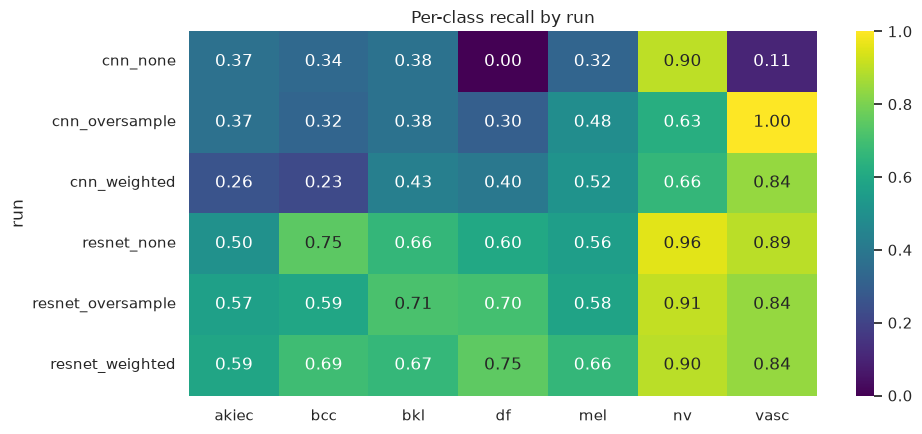

In [7]:
rows = {}
for run in runs:
    y_true, y_pred, _ = preds_cache[run]
    rep = per_class_report(y_true, y_pred)
    rows[run] = {c: rep[c]["recall"] for c in CLASSES}
recall_tab = pd.DataFrame(rows).T[CLASSES]
plt.figure(figsize=(10, 4.5))
sns.heatmap(recall_tab, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Per-class recall by run"); plt.ylabel("run"); plt.tight_layout()
plt.savefig("figures/per_class_recall.png", dpi=120); plt.show()

### Redefining "best model": a malignant lesion called benign

Every ranking so far treats "getting a class wrong" as equally bad
regardless of which wrong class it lands on. Clinically, it isn't:

- mel (melanoma), bcc (basal cell carcinoma) and akiec (actinic
  keratosis) are the malignant / premalignant classes,
  they may need a biopsy or excision after a clinical evaluation.
- bkl, df, nv, vasc are benign, so they usually mean no meaningful risk on their own.

The failure mode that actually matters is a malignant/premalignant lesion
being predicted as one of the benign classes. Being wrong within the
malignant group (e.g. a melanoma called bcc) is still an error, but a
safer one, cause it still routes the patient toward a treatment, where the correct
diagnosis would likely surface. So the metric we actually want is:

P(predicted in benign | true in malignant), which corresponds to the "malignant called benign" rate. This is what determines the model we carry forward into
the interpretability phase.

In [ ]:
MALIGNANT = ["mel", "bcc", "akiec"]
BENIGN = ["bkl", "df", "nv", "vasc"]
malignant_idx = [CLASSES.index(c) for c in MALIGNANT]
benign_idx = [CLASSES.index(c) for c in BENIGN]
mel_idx = CLASSES.index("mel")

def malignant_missed_as_benign(y_true, y_pred, malignant_class=None):
    target_idx = malignant_idx if malignant_class is None else [CLASSES.index(malignant_class)]
    mask = np.isin(y_true, target_idx)
    if mask.sum() == 0:
        return float("nan")
    return np.isin(y_pred[mask], benign_idx).mean()

def clinical_table_for(cache):
    rows = {}
    for run in runs:
        y_true, y_pred, _ = cache[run]
        rows[run] = {
            "malignant_missed_as_benign": malignant_missed_as_benign(y_true, y_pred),
            "mel_missed_as_benign": malignant_missed_as_benign(y_true, y_pred, "mel"),
            "bcc_missed_as_benign": malignant_missed_as_benign(y_true, y_pred, "bcc"),
            "akiec_missed_as_benign": malignant_missed_as_benign(y_true, y_pred, "akiec"),
        }
    return pd.DataFrame(rows).T.sort_values("malignant_missed_as_benign")

# Selection
val_clinical = clinical_table_for(val_cache)
print("Validation (used for selection):")
display(val_clinical.round(3))

val_table = pd.DataFrame(val_results).T
val_mel_recall = pd.Series({run: (val_cache[run][1][val_cache[run][0] == mel_idx] == mel_idx).mean()
                            for run in runs})
by_macro_f1 = val_table["macro_f1"].idxmax()
by_mel_recall = val_mel_recall.idxmax()
best_run_clinical = val_clinical.index[0]

print(f"Best by macro-F1                   : {by_macro_f1:<17} macro_f1={val_table.loc[by_macro_f1, 'macro_f1']:.3f}")
print(f"Best by melanoma recall            : {by_mel_recall:<17} mel_recall={val_mel_recall[by_mel_recall]:.2f}")
print(f"Best by malignant-missed-as-benign : {best_run_clinical:<17} "
      f"rate={val_clinical.loc[best_run_clinical, 'malignant_missed_as_benign']:.3f}")

# Report: test set
test_clinical = clinical_table_for(preds_cache)
print("\nTest (report only, not used for selection):")
display(test_clinical.round(3))

Validation (used for selection):


,malignant_missed_as_benign,mel_missed_as_benign,bcc_missed_as_benign,akiec_missed_as_benign
resnet_weighted,0.248,0.312,0.117,0.235
cnn_oversample,0.275,0.294,0.312,0.157
resnet_none,0.319,0.441,0.117,0.216
resnet_oversample,0.349,0.447,0.195,0.255
cnn_weighted,0.393,0.371,0.519,0.275
cnn_none,0.456,0.606,0.325,0.157


Best by macro-F1                   : resnet_weighted   macro_f1=0.706
Best by melanoma recall            : resnet_weighted   mel_recall=0.62
Best by malignant-missed-as-benign : resnet_weighted   rate=0.248

Test (report only, not used for selection):


,malignant_missed_as_benign,mel_missed_as_benign,bcc_missed_as_benign,akiec_missed_as_benign
resnet_weighted,0.248,0.279,0.183,0.239
resnet_none,0.333,0.400,0.169,0.348
cnn_oversample,0.344,0.358,0.380,0.239
resnet_oversample,0.351,0.388,0.268,0.348
cnn_weighted,0.422,0.388,0.507,0.413
cnn_none,0.472,0.582,0.324,0.304


## 4. Confusion matrix of best model

Row-normalized, so each row shows where true examples of that class were
sent. The diagonal is recall, off-diagonal cells are the mistakes.

We plot, on the test set, the run with the lowest malignant-called-benign
rate on validation (chosen above), since that is the most suitable model
for the specific task under examination.

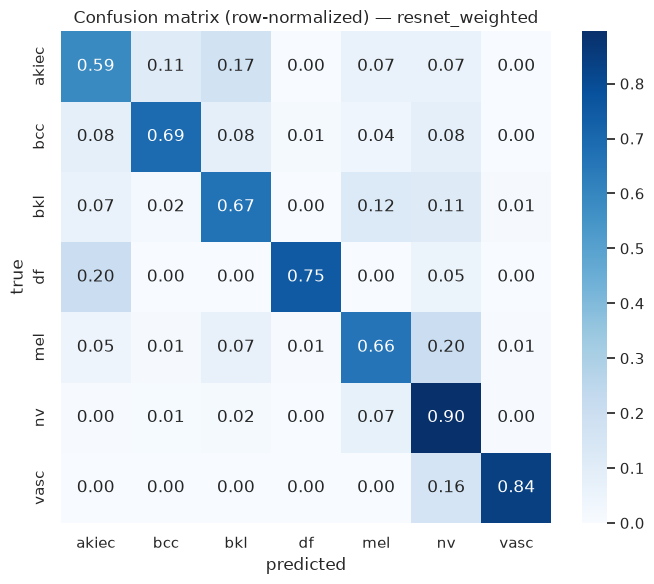

best run: resnet_weighted


In [ ]:
best_run = best_run_clinical
y_true, y_pred, _ = preds_cache[best_run]
cm = confusion(y_true, y_pred, normalize="true")
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title(f"Confusion matrix (row-normalized) — {best_run}")
plt.xlabel("predicted"); plt.ylabel("true"); plt.tight_layout()
plt.savefig("figures/confusion_best.png", dpi=120); plt.show()
print("best run:", best_run)